In [1]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from PIL import Image
from tqdm import tqdm
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Using device: cuda


In [2]:
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 4:
        print(root, "| subfolders:", len(dirs), "| files:", len(files))

/kaggle/input | subfolders: 1 | files: 0
/kaggle/input/datasets | subfolders: 1 | files: 0
/kaggle/input/datasets/faysalahmed7676 | subfolders: 1 | files: 0
/kaggle/input/datasets/faysalahmed7676/riceleafdiseases | subfolders: 1 | files: 0
/kaggle/input/datasets/faysalahmed7676/riceleafdiseases/RiceLeafDisease-BD5 A Field-Collected Five-Class I | subfolders: 1 | files: 0


In [8]:
BASE = "/kaggle/input/datasets/faysalahmed7676/riceleafdiseases"

expected = {"Blast", "Narrow_Brown_Spot", "Normal_Leaf", "Sheath_Blight", "Tungro"}
DATA_DIR = None
for root, dirs, files in os.walk(BASE):
    if expected.issubset(set(dirs)):
        DATA_DIR = root
        break

print("DATA_DIR found:", DATA_DIR)
assert DATA_DIR is not None, "Class folders not found. Check BASE path (see debug cell below)."

classes = sorted(expected)
class_to_idx = {c: i for i, c in enumerate(classes)}
exts = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")

image_paths, labels = [], []
for c in classes:
    files = [os.path.join(DATA_DIR, c, f) for f in os.listdir(os.path.join(DATA_DIR, c))
             if f.endswith(exts)]
    image_paths += files
    labels += [class_to_idx[c]] * len(files)
    print(f"  {c:20s}: {len(files)} images")

label_names = [classes[l] for l in labels]   # used later for the class distribution plot
print("Total images:", len(image_paths))

DATA_DIR found: /kaggle/input/datasets/faysalahmed7676/riceleafdiseases/RiceLeafDisease-BD5 A Field-Collected Five-Class I/RiceLeafDisease-BD5/RiceLeafBD
  Blast               : 720 images
  Narrow_Brown_Spot   : 476 images
  Normal_Leaf         : 834 images
  Sheath_Blight       : 626 images
  Tungro              : 494 images
Total images: 3150


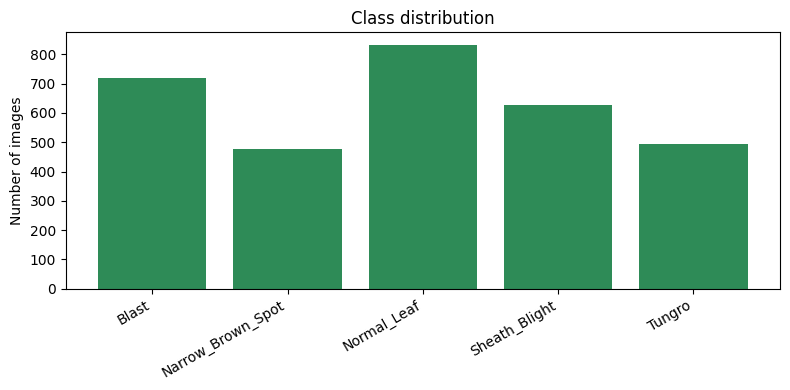

In [9]:
counts = [label_names.count(c) for c in classes]
plt.figure(figsize=(8, 4))
plt.bar(classes, counts, color="seagreen")
plt.xticks(rotation=30, ha="right"); plt.ylabel("Number of images")
plt.title("Class distribution"); plt.tight_layout(); plt.show()

In [10]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=SEED)

print("Train:", len(train_paths), "| Val:", len(val_paths), "| Test:", len(test_paths))

Train: 2205 | Val: 472 | Test: 473


In [11]:
IMG_SIZE = 128
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tfms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class RiceDataset(Dataset):
    def __init__(self, paths, labels, transform, size=IMG_SIZE):
        self.labels, self.transform = labels, transform
        self.imgs = [Image.open(p).convert("RGB").resize((size, size))
                     for p in tqdm(paths, desc="Loading images")]
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, idx):
        return self.transform(self.imgs[idx]), torch.tensor(self.labels[idx], dtype=torch.long)
    def collate_fn(self, batch):
        imgs, lbls = zip(*batch)
        return torch.stack(imgs).to(device), torch.stack(lbls).to(device)

BATCH_SIZE = 32
train_ds = RiceDataset(train_paths, train_labels, train_tfms)
val_ds   = RiceDataset(val_paths,   val_labels,   eval_tfms)
test_ds  = RiceDataset(test_paths,  test_labels,  eval_tfms)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  collate_fn=train_ds.collate_fn)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=val_ds.collate_fn)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=test_ds.collate_fn)

Loading images: 100%|██████████| 473/473 [00:47<00:00, 10.00it/s]


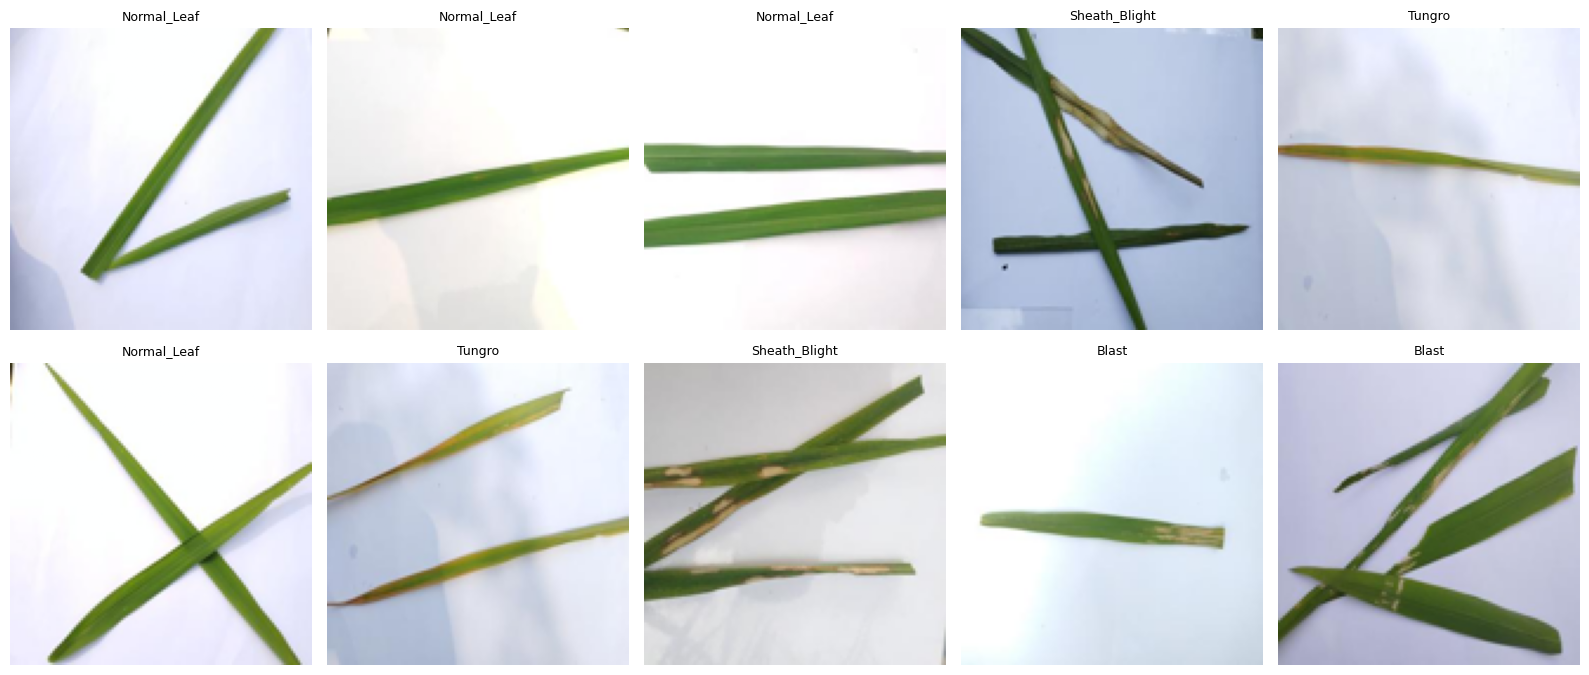

In [12]:
def show_samples(ds, n=10):
    fig, axes = plt.subplots(2, n // 2, figsize=(16, 7))
    for ax, i in zip(axes.flat, random.sample(range(len(ds)), n)):
        img, lbl = ds[i]
        img = img * torch.tensor(std).view(3,1,1) + torch.tensor(mean).view(3,1,1)
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(classes[lbl], fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

show_samples(val_ds)

In [13]:
train_counts = np.bincount(train_labels, minlength=len(classes))
class_weights = torch.tensor(len(train_labels) / (len(classes) * train_counts),
                             dtype=torch.float32).to(device)
print("Class weights:", dict(zip(classes, class_weights.cpu().numpy().round(2))))

def get_model(num_classes=len(classes)):
    feat = 128 * (IMG_SIZE // 8) * (IMG_SIZE // 8)
    model = nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1),  nn.BatchNorm2d(32),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64),  nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1),nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(feat, 256), nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(256, num_classes),
    ).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = Adam(model.parameters(), lr=1e-3)
    return model, loss_fn, optimizer

model, loss_fn, optimizer = get_model()
print(model)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Class weights: {'Blast': np.float32(0.88), 'Narrow_Brown_Spot': np.float32(1.32), 'Normal_Leaf': np.float32(0.76), 'Sheath_Blight': np.float32(1.01), 'Tungro': np.float32(1.27)}
Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1

In [19]:
def train_batch(x, y, model, optimizer, loss_fn):
    model.train()
    prediction = model(x)
    batch_loss = loss_fn(prediction, y)
    batch_loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    return batch_loss.item()

@torch.no_grad()
def accuracy(x, y, model):
    model.eval()
    prediction = model(x)
    _, argmaxes = prediction.max(-1)
    return (argmaxes == y).cpu().numpy().tolist()

@torch.no_grad()
def val_loss(x, y, model):
    model.eval()
    prediction = model(x)
    return loss_fn(prediction, y).item()

In [20]:
EPOCHS = 50
train_losses, train_accuracies, val_losses, val_accuracies = [], [], [], []
best_val_acc = 0

for epoch in range(EPOCHS):
    t0 = time.time()
    batch_losses, batch_accs = [], []
    for x, y in train_dl:
        batch_losses.append(train_batch(x, y, model, optimizer, loss_fn))
        batch_accs.extend(accuracy(x, y, model))
    train_loss, train_acc = np.mean(batch_losses), np.mean(batch_accs)

    v_losses, v_accs = [], []
    for x, y in val_dl:
        v_losses.append(val_loss(x, y, model))
        v_accs.extend(accuracy(x, y, model))
    v_loss, v_acc = np.mean(v_losses), np.mean(v_accs)

    train_losses.append(train_loss); train_accuracies.append(train_acc)
    val_losses.append(v_loss);       val_accuracies.append(v_acc)

    if v_acc > best_val_acc:
        best_val_acc = v_acc
        torch.save(model.state_dict(), "best_model.pth")

    print(f"Epoch {epoch+1:02d}/{EPOCHS} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
          f"val loss {v_loss:.4f} acc {v_acc:.4f} | {time.time()-t0:.1f}s")

print("Best validation accuracy:", best_val_acc)

Epoch 01/50 | train loss 3.1185 acc 0.3175 | val loss 1.4213 acc 0.3686 | 6.0s
Epoch 02/50 | train loss 1.4314 acc 0.3977 | val loss 1.1437 acc 0.4979 | 5.1s
Epoch 03/50 | train loss 1.2480 acc 0.4707 | val loss 1.0477 acc 0.5169 | 5.1s
Epoch 04/50 | train loss 1.1820 acc 0.5156 | val loss 0.9599 acc 0.5678 | 5.1s
Epoch 05/50 | train loss 1.0805 acc 0.5651 | val loss 1.0741 acc 0.5742 | 5.1s
Epoch 06/50 | train loss 1.0629 acc 0.5528 | val loss 0.9523 acc 0.5869 | 5.1s
Epoch 07/50 | train loss 1.0025 acc 0.5968 | val loss 0.8687 acc 0.6271 | 5.1s
Epoch 08/50 | train loss 1.0273 acc 0.5905 | val loss 0.7993 acc 0.6695 | 5.1s
Epoch 09/50 | train loss 1.0156 acc 0.6331 | val loss 0.8235 acc 0.6907 | 5.2s
Epoch 10/50 | train loss 0.9740 acc 0.6168 | val loss 0.7643 acc 0.6314 | 5.1s
Epoch 11/50 | train loss 0.9485 acc 0.6567 | val loss 0.9110 acc 0.6229 | 5.1s
Epoch 12/50 | train loss 0.9582 acc 0.6499 | val loss 0.8118 acc 0.6229 | 5.1s
Epoch 13/50 | train loss 0.9495 acc 0.6363 | val los

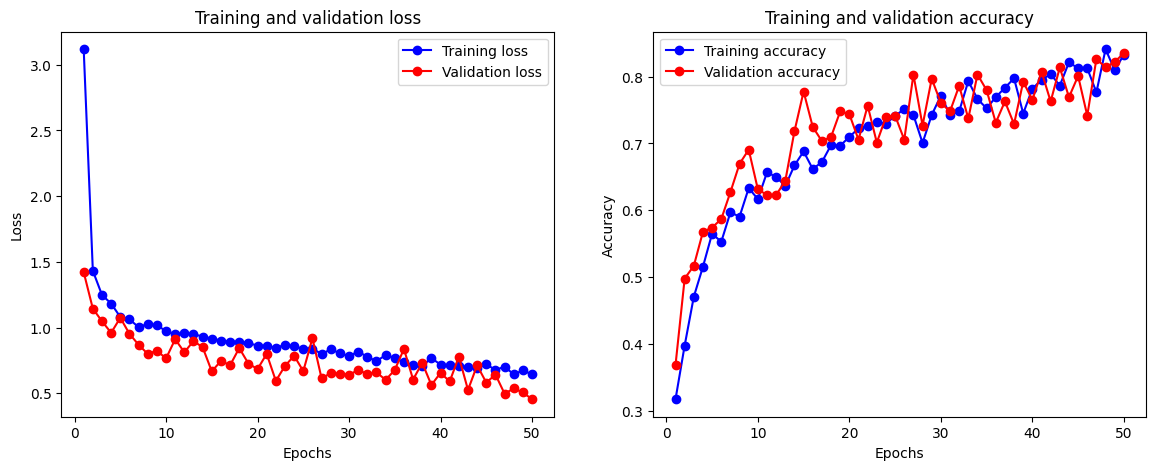

In [22]:
epochs = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(epochs, train_losses, "bo-", label="Training loss")
ax[0].plot(epochs, val_losses, "r-o", label="Validation loss")
ax[0].set_title("Training and validation loss"); ax[0].set_xlabel("Epochs"); ax[0].set_ylabel("Loss"); ax[0].legend()

ax[1].plot(epochs, train_accuracies, "bo-", label="Training accuracy")
ax[1].plot(epochs, val_accuracies, "r-o", label="Validation accuracy")
ax[1].set_title("Training and validation accuracy"); ax[1].set_xlabel("Epochs"); ax[1].set_ylabel("Accuracy"); ax[1].legend()
plt.show()

In [23]:
model.load_state_dict(torch.load("best_model.pth"))
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for x, y in test_dl:
        _, pred = model(x).max(-1)
        all_preds += pred.cpu().tolist()
        all_true  += y.cpu().tolist()

all_preds, all_true = np.array(all_preds), np.array(all_true)
print(f"Test accuracy : {np.mean(all_preds == all_true):.4f}")
print(f"Macro F1-score: {f1_score(all_true, all_preds, average='macro'):.4f}")
print(f"Majority-class baseline: {max(np.bincount(all_true)) / len(all_true):.4f}")

Test accuracy : 0.8414
Macro F1-score: 0.8399
Majority-class baseline: 0.2643


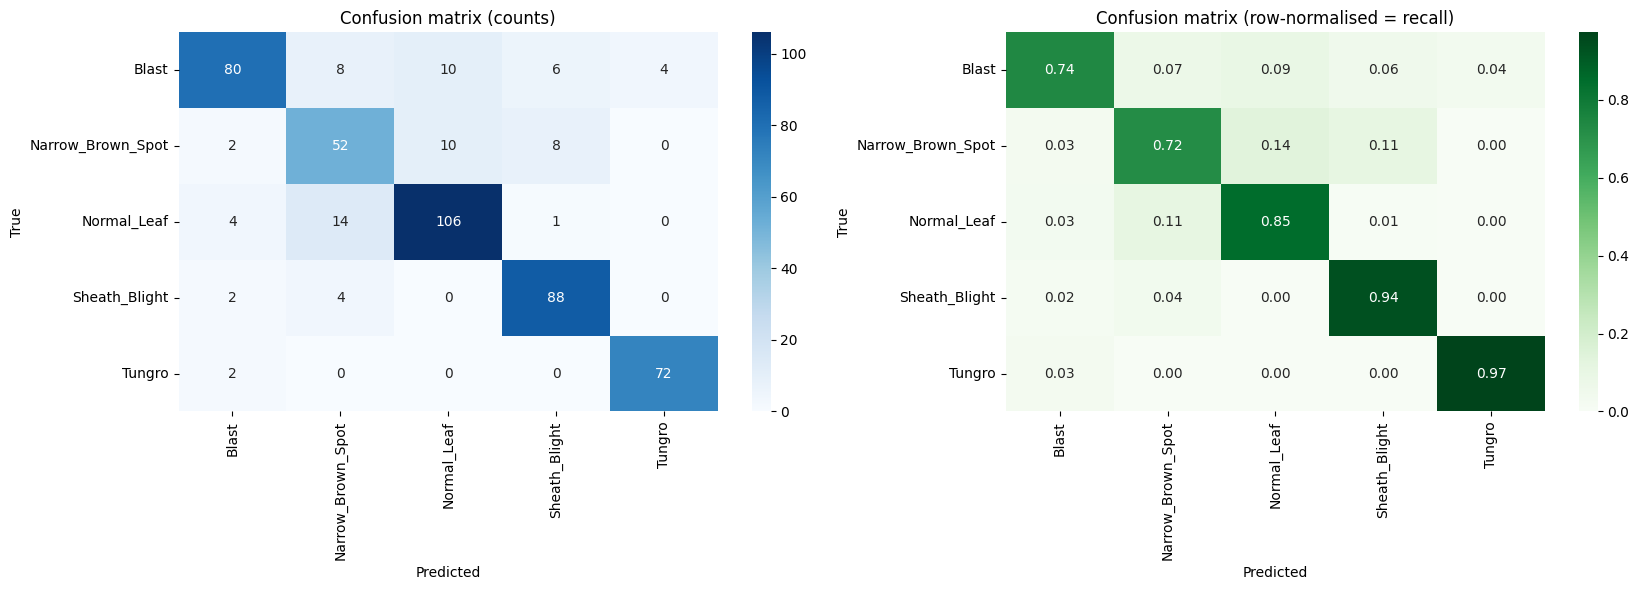

                   precision    recall  f1-score   support

            Blast     0.8889    0.7407    0.8081       108
Narrow_Brown_Spot     0.6667    0.7222    0.6933        72
      Normal_Leaf     0.8413    0.8480    0.8446       125
    Sheath_Blight     0.8544    0.9362    0.8934        94
           Tungro     0.9474    0.9730    0.9600        74

         accuracy                         0.8414       473
        macro avg     0.8397    0.8440    0.8399       473
     weighted avg     0.8448    0.8414    0.8410       473



In [24]:
cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set_title("Confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Greens", xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set_title("Confusion matrix (row-normalised = recall)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
plt.tight_layout(); plt.show()

print(classification_report(all_true, all_preds, target_names=classes, digits=4))

Misclassified: 75 of 473


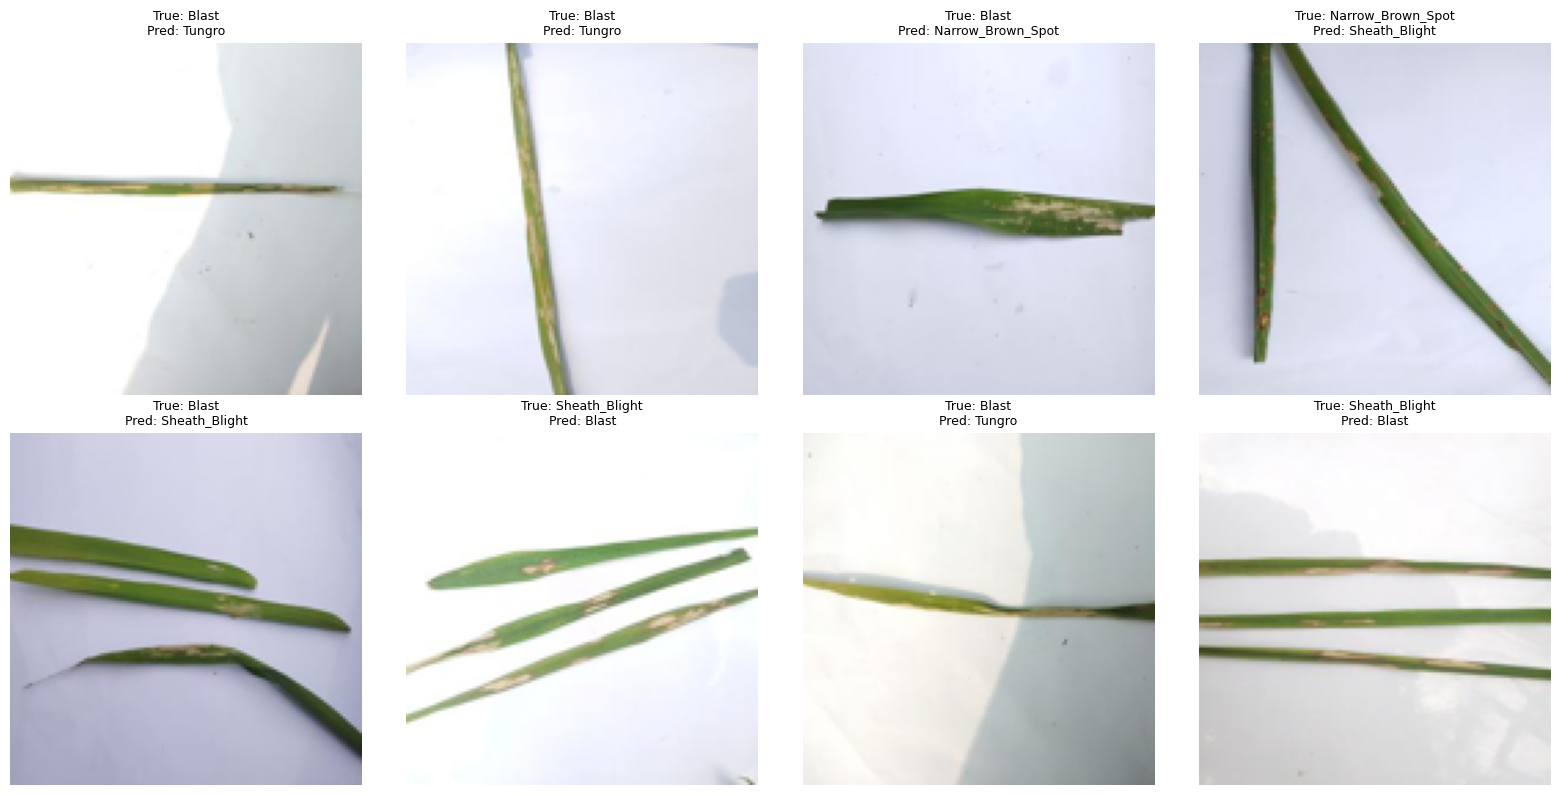

In [25]:
wrong = np.where(all_preds != all_true)[0]
print("Misclassified:", len(wrong), "of", len(all_true))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axes.flat, wrong[:8]):
    img, _ = test_ds[i]
    img = img * torch.tensor(std).view(3,1,1) + torch.tensor(mean).view(3,1,1)
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"True: {classes[all_true[i]]}\nPred: {classes[all_preds[i]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()